# Phase 2 · Data visualization

**Project 1 · FAA · breast_cancer (classification)**

**What this notebook does:** it looks at the data *before* using any model and, from every plot, draws a **decision** for the following phases.

**How to read it:** every code cell has a comment on each line. Below each result there is a *What we see / Decision* box.

**Important:** we only explore the **training set** (455 rows). The 114 test rows are not looked at.

### Cell 1: import the libraries

We load the libraries. Each one has a role: **polars** for the table, **numpy** for the calculations, **matplotlib/seaborn** for the plots, **scipy** for skewness and **scikit-learn** only to split the data.

In [1]:
import polars as pl  # polars: reads and manipulates the data table
import numpy as np  # numpy: numerical computing with arrays
import matplotlib.pyplot as plt  # matplotlib: draws the plots
import seaborn as sns  # seaborn: nicer statistical plots
from pathlib import Path  # Path: handles folder and file paths
from scipy.stats import skew  # skew: measures the asymmetry of a distribution
from sklearn.model_selection import train_test_split  # train_test_split: separates train and test

### Cell 2: load the data file

We read the course file. It is a `.csv.zst` (compressed CSV) and polars opens it directly.

In [2]:
path = Path("datasets/breast_cancer.csv.zst")  # the data file is in the datasets folder
data = pl.read_csv(path)  # read the compressed file with polars
figures_dir = path.parent.parent / "figures" / "02_visualization"  # folder where we will save the plots
figures_dir.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
print("Rows:", data.height)  # number of tumours
print("Columns:", data.width)  # number of columns (30 features + the diagnosis)

Rows: 569
Columns: 31


### Cell 3: recode the diagnosis

In the file, `target = 1` means **benign**. So that "positive" is the **malignant** tumour (the one we do not want to miss) we create `malignant = 1 - target`.

In [3]:
data = data.with_columns((1 - pl.col("target")).alias("malignant"))  # in the file target=1 is BENIGN; we create malignant=1 so that "positive" is the malignant tumour
data = data.drop("target")  # drop the old column to avoid confusion
print(data["malignant"].value_counts().sort("malignant"))  # check how many of each type (0 = benign, 1 = malignant)

shape: (2, 2)
┌───────────┬───────┐
│ malignant ┆ count │
│ ---       ┆ ---   │
│ i64       ┆ u32   │
╞═══════════╪═══════╡
│ 0         ┆ 357   │
│ 1         ┆ 212   │
└───────────┴───────┘


**What we see:** 357 benign and 212 malignant tumours in total. **Decision:** from now on `malignant = 1` is the positive class.

### Cell 4: split train and test BEFORE looking at the data

**Golden rule:** we split train and test *before* looking at anything. From here on we only explore `train`; `test` is kept for the end (Phase 6). This way nothing we see can contaminate the final exam.

In [4]:
indices = np.arange(data.height)  # list of row numbers 0, 1, 2, ...
train_indices, test_indices = train_test_split(  # split the rows into two groups
    indices,  # the rows to distribute
    test_size=0.20,  # 20% is kept for the final test
    random_state=42,  # fixed seed: the split is always the same
    stratify=data["malignant"].to_numpy(),  # keeps the same share of malignant tumours in both groups
)
train = data[train_indices.tolist()]  # training table: the only one we will look at
test = data[test_indices.tolist()]  # test table: not touched until the end
print("Train:", train.height, "rows")  # training size
print("Test:", test.height, "rows")  # test size

Train: 455 rows
Test: 114 rows


**What we see:** 455 training rows and 114 test rows, with the same share of malignant tumours (`stratify`). **Decision:** seed 42 stays fixed throughout the project.

### Cell 5: first rows

Let us see what the table looks like.

In [5]:
train.head(5)  # show the first 5 rows of the training set

mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,radius_error,texture_error,perimeter_error,area_error,smoothness_error,compactness_error,concavity_error,concave_points_error,symmetry_error,fractal_dimension_error,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,malignant
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
16.02,23.24,102.7,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,0.3795,1.187,2.466,40.51,0.004029,0.009269,0.01101,0.007591,0.0146,0.003042,19.19,33.88,123.8,1150.0,0.1181,0.1551,0.1459,0.09975,0.2948,0.08452,1
12.32,12.39,78.85,464.1,0.1028,0.06981,0.03987,0.037,0.1959,0.05955,0.236,0.6656,1.67,17.43,0.008045,0.0118,0.01683,0.01241,0.01924,0.002248,13.5,15.64,86.97,549.1,0.1385,0.1266,0.1242,0.09391,0.2827,0.06771,0
12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.158,0.06114,0.4993,1.798,2.552,41.24,0.006011,0.0448,0.05175,0.01341,0.02669,0.007731,14.4,27.01,91.63,645.8,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151,0
14.9,22.53,102.1,685.0,0.09947,0.2225,0.2733,0.09711,0.2041,0.06898,0.253,0.8749,3.466,24.19,0.006965,0.06213,0.07926,0.02234,0.01499,0.005784,16.35,27.57,125.4,832.7,0.1419,0.709,0.9019,0.2475,0.2866,0.1155,1
18.61,20.25,122.1,1094.0,0.0944,0.1066,0.149,0.07731,0.1697,0.05699,0.8529,1.849,5.632,93.54,0.01075,0.02722,0.05081,0.01911,0.02293,0.004217,21.31,27.26,139.9,1403.0,0.1338,0.2117,0.3446,0.149,0.2341,0.07421,1


### Cell 6: distribution of the diagnosis

**Target (y):** how many tumours of each type are there? If a class were very rare, accuracy would be misleading.

shape: (2, 2)
┌───────────┬─────┐
│ malignant ┆ len │
│ ---       ┆ --- │
│ i64       ┆ u32 │
╞═══════════╪═════╡
│ 0         ┆ 285 │
│ 1         ┆ 170 │
└───────────┴─────┘
malignant=0: 285 cases (62.6%)
malignant=1: 170 cases (37.4%)


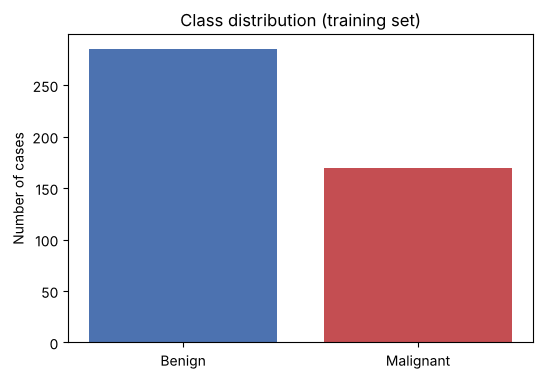

In [6]:
counts = train.group_by("malignant").len().sort("malignant")  # count how many tumours of each type
print(counts)  # show the count table
total = counts["len"].sum()  # total number of training rows
for kind, amount in zip(counts["malignant"], counts["len"]):  # loop over each type
    print(f"malignant={kind}: {amount} cases ({amount / total:.1%})")  # show the percentage of each type
plt.figure(figsize=(6, 4))  # create a 6x4 inch figure
plt.bar(["Benign", "Malignant"], counts["len"].to_list(), color=["#4C72B0", "#C44E52"])  # bars: blue benign, red malignant
plt.title("Class distribution (training set)")  # plot title
plt.ylabel("Number of cases")  # vertical axis name
plt.savefig(figures_dir / "01_classes.png", bbox_inches="tight")  # save the plot as an image
plt.show()  # show it on screen

**What we see:** 62.6% benign and 37.4% malignant. There is a moderate imbalance, not an extreme one.

**Decision:** (1) use **stratified** splits; (2) do not use accuracy as the main metric, because "always predict benign" already gets 62.6%; we will use **MCC** and the **recall** of the malignant class; (3) that 62.6% will be our baseline.

### Cell 7: list of features

**Features (X):** we list the 30 numeric columns. They are 10 measurements of the cell nucleus (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) × 3 versions (`mean` = average, `_error` = standard error, `worst` = most extreme value).

In [7]:
columns = [c for c in train.columns if c != "malignant"]  # all columns except the diagnosis
print("Number of features:", len(columns))  # must be 30
for i, name in enumerate(columns):  # loop over the names with their number
    print(i + 1, name)  # print them numbered

Number of features: 30
1 mean_radius
2 mean_texture
3 mean_perimeter
4 mean_area
5 mean_smoothness
6 mean_compactness
7 mean_concavity
8 mean_concave_points
9 mean_symmetry
10 mean_fractal_dimension
11 radius_error
12 texture_error
13 perimeter_error
14 area_error
15 smoothness_error
16 compactness_error
17 concavity_error
18 concave_points_error
19 symmetry_error
20 fractal_dimension_error
21 worst_radius
22 worst_texture
23 worst_perimeter
24 worst_area
25 worst_smoothness
26 worst_compactness
27 worst_concavity
28 worst_concave_points
29 worst_symmetry
30 worst_fractal_dimension


### Cell 8: choose 6 features to look at closely

**Distributions.** We do not plot all 30; we pick 6 that illustrate different problems (size, standard error, shape, smoothness, texture).

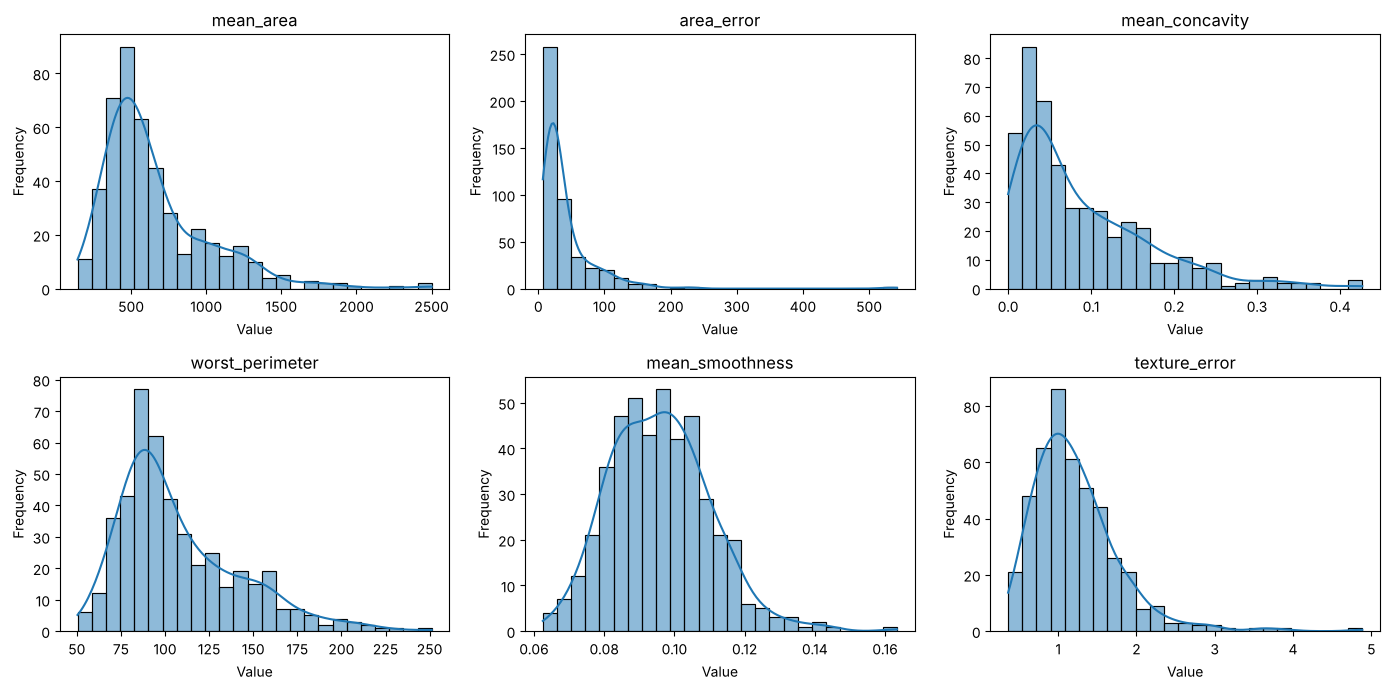

In [8]:
selected = ["mean_area", "area_error", "mean_concavity", "worst_perimeter", "mean_smoothness", "texture_error"]  # each one illustrates a different issue
fig, axes = plt.subplots(2, 3, figsize=(14, 7))  # grid of 2 rows and 3 columns
for ax, column in zip(axes.ravel(), selected):  # one feature per panel
    values = train[column].to_numpy()  # convert the column to a numpy array
    sns.histplot(values, bins=25, kde=True, ax=ax)  # histogram with the density curve
    ax.set_title(column)  # title: feature name
    ax.set_xlabel("Value")  # horizontal axis name
    ax.set_ylabel("Frequency")  # vertical axis name
plt.tight_layout()  # adjust spacing so nothing overlaps
plt.savefig(figures_dir / "02_histograms.png", bbox_inches="tight")  # save the image
plt.show()  # show it

**What we see:** `mean_area` and `area_error` have a long right tail; `mean_concavity` too; `mean_smoothness` is almost a bell curve. **Decision:** we will have to decide whether to transform (see cells 13-14).

### Cell 9: scales (are all features in the same range?)

**Scales.** We compare the range of the features: are they all on the same order of magnitude?

In [9]:
medians = {c: float(np.median(train[c].to_numpy())) for c in columns}  # median of each feature
for column in selected:  # show min, median and max of the 6 chosen features
    values = train[column]  # current column
    print(f"{column}: min {values.min():.4f} | median {medians[column]:.4f} | max {values.max():.4f}")  # one line per feature
largest = max(medians, key=medians.get)  # feature with the largest median
smallest = min(medians, key=medians.get)  # feature with the smallest median
print(f"\nLargest median: {largest} = {medians[largest]:.1f}")  # its value
print(f"Smallest median: {smallest} = {medians[smallest]:.4f}")  # its value
print(f"The largest is {medians[largest] / medians[smallest]:,.0f} times the smallest")  # how many times larger

mean_area: min 143.5000 | median 546.4000 | max 2501.0000
area_error: min 6.8020 | median 24.8700 | max 542.2000
mean_concavity: min 0.0000 | median 0.0594 | max 0.4268
worst_perimeter: min 50.4100 | median 97.6500 | max 251.2000
mean_smoothness: min 0.0625 | median 0.0952 | max 0.1634
texture_error: min 0.3602 | median 1.1390 | max 4.8850

Largest median: worst_area = 683.4
Smallest median: fractal_dimension_error = 0.0031
The largest is 218,269 times the smallest


**What we see:** the medians go from ~0.003 (`fractal_dimension_error`) to ~683 (`worst_area`): a difference of about **218,000 times**.

**Decision:** **standardize** (mean 0, standard deviation 1) for the models that measure distances or weights (SVM, MLP, evolutionary). The tree does not need it. The scaling will be learned only from the training part of each fold (Phase 3).

### Cell 10: missing values and duplicates

**Missing values and duplicates.** We check that the table is clean.

In [10]:
nulls = train.null_count().row(0)  # nulls in each column (one row of results)
print("Total null values:", sum(nulls))  # sum of all nulls
total_nan = sum(int(np.isnan(train[c].to_numpy()).sum()) for c in columns)  # NaN (invalid number) in each column
print("Total NaN values:", total_nan)  # sum of all NaN
print("Duplicated rows:", int(train.is_duplicated().sum()))  # repeated rows

Total null values: 0
Total NaN values: 0
Duplicated rows: 0


**What we see:** 0 nulls, 0 NaN, 0 duplicates. **Decision:** there is nothing to impute or remove.

### Cell 11: outliers (box plots)

**Outliers, graphical view.** In a box plot, the isolated points beyond the whiskers are possible outliers.

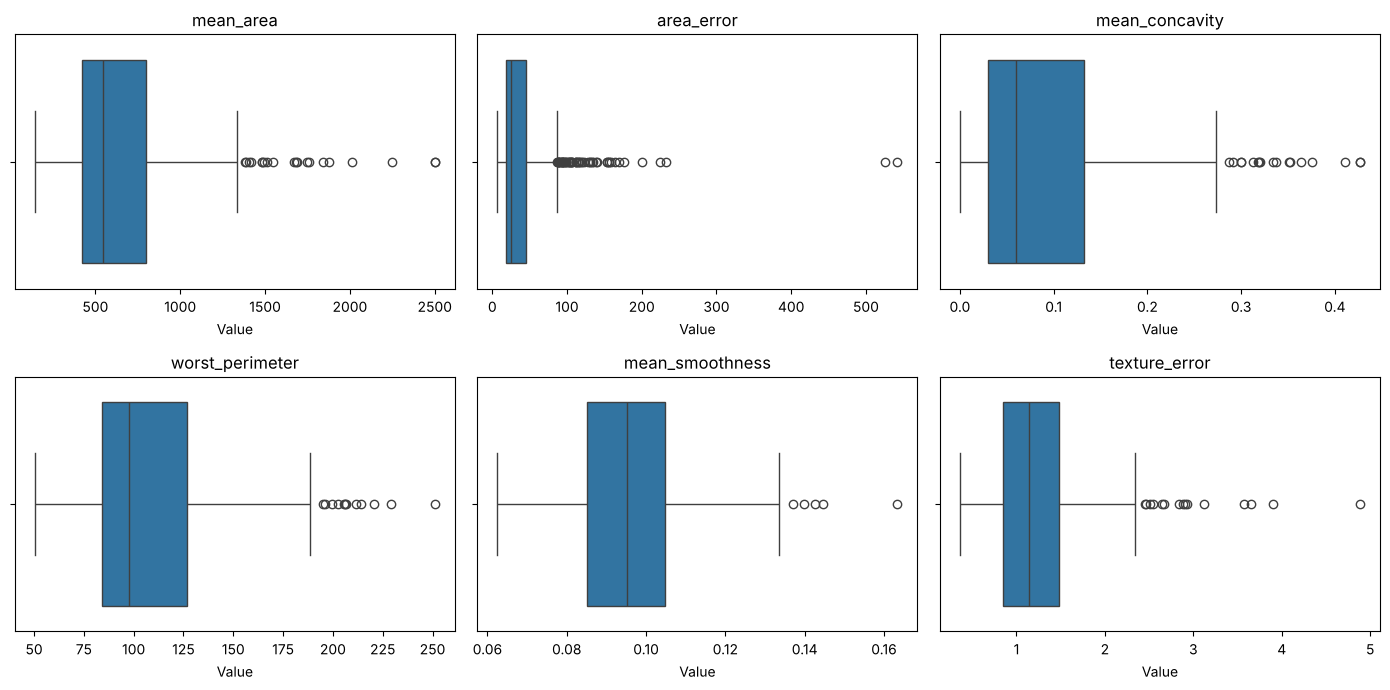

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))  # 2x3 grid
for ax, column in zip(axes.ravel(), selected):  # one feature per panel
    values = train[column].to_numpy()  # convert the column to numpy
    sns.boxplot(x=values, ax=ax)  # box: the isolated points are possible outliers
    ax.set_title(column)  # panel title
    ax.set_xlabel("Value")  # horizontal axis name
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "03_outliers.png", bbox_inches="tight")  # save the image
plt.show()  # show it

### Cell 12: count the outliers with the IQR rule

**Outliers, exact count.** We use Tukey's rule: a value is an outlier if it falls outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

In [12]:
def count_outliers(values):  # function: flags which values are outliers
    q1 = np.quantile(values, 0.25)  # first quartile (25% of the data below)
    q3 = np.quantile(values, 0.75)  # third quartile (75% of the data below)
    iqr = q3 - q1  # interquartile range: width of the box
    outside = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)  # True if the value falls outside the 1.5·IQR rule
    return outside  # array of True/False, one per row

for column in selected:  # count in the 6 chosen features
    print(column, ":", int(count_outliers(train[column].to_numpy()).sum()), "possible outliers")  # how many there are

outside_all = np.column_stack([count_outliers(train[c].to_numpy()) for c in columns])  # True/False table for the 30 features
has_any = outside_all.any(axis=1)  # True if the tumour has at least one outlier
malignant = train["malignant"].to_numpy()  # diagnosis of each row (1 = malignant)
print(f"\nTumours with any outlier: {has_any.sum()} of {len(has_any)} ({has_any.mean():.0%})")  # total and percentage
print(f"  among malignant: {has_any[malignant == 1].mean():.0%}")  # percentage within malignant tumours
print(f"  among benign: {has_any[malignant == 0].mean():.0%}")  # percentage within benign tumours

mean_area : 20 possible outliers
area_error : 53 possible outliers
mean_concavity : 17 possible outliers
worst_perimeter : 12 possible outliers
mean_smoothness : 5 possible outliers
texture_error : 15 possible outliers

Tumours with any outlier: 135 of 455 (30%)
  among malignant: 52%
  among benign: 16%


**What we see:** `area_error` has 53 outliers (12% of the rows). Overall, **135 of 455 tumours (30%) have some outlier**, but they are **52% of the malignant tumours** against **16% of the benign ones**.

**Decision:** **do not remove outliers**. They are not measurement errors: they are the large, irregular tumours, precisely the ones we want to detect. Deleting them would remove malignant cases.

### Cell 13: skewness of the distributions

**Skewness.** `skew > 1` means a long right tail (a few very large values). We test whether `log1p` (= log(1 + x)) reduces it.

In [13]:
skews = {c: float(skew(train[c].to_numpy())) for c in columns}  # skewness of each feature (0 = symmetric)
very_skewed = [c for c in columns if skews[c] > 1]  # those with a long right tail
print("Features with skewness > 1:", len(very_skewed), "of", len(columns))  # how many
most_skewed = sorted(skews, key=skews.get, reverse=True)[:5]  # the 5 most skewed
for c in most_skewed:  # show them
    print(f"  {c}: {skews[c]:.2f}")  # name and skewness
before = np.mean([skews[c] for c in very_skewed])  # mean skewness of those features
after = np.mean([skew(np.log1p(train[c].to_numpy())) for c in very_skewed])  # the same after applying log1p
print(f"Mean skewness of those features: before {before:.2f}, after log1p {after:.2f}")  # compare

Features with skewness > 1: 23 of 30
  area_error: 5.48
  concavity_error: 5.37
  fractal_dimension_error: 4.07
  perimeter_error: 3.51
  radius_error: 3.17
Mean skewness of those features: before 2.15, after log1p 1.40


**What we see:** 23 of the 30 features have skewness > 1; the worst are `area_error` (5.5) and `concavity_error` (5.4). `log1p` lowers the mean skewness from 2.15 to 1.40.

**Decision:** `log1p` is an **option** of the preprocessing (tested in Phase 5), not an obligation. It is not applied to the tree, which is unaffected by monotonic transformations.

### Cell 14: effect of log1p on one feature

We see the effect of `log1p` on the most skewed feature.

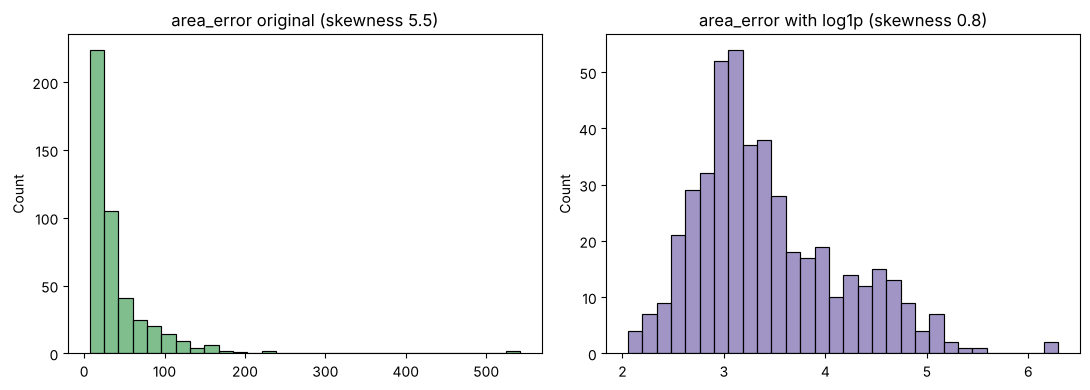

In [14]:
values = train["area_error"].to_numpy()  # take area_error, very skewed
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # two plots side by side
sns.histplot(values, bins=30, ax=axes[0], color="#55A868")  # original histogram
axes[0].set_title(f"area_error original (skewness {skew(values):.1f})")  # title with its skewness
sns.histplot(np.log1p(values), bins=30, ax=axes[1], color="#8172B2")  # histogram after log1p
axes[1].set_title(f"area_error with log1p (skewness {skew(np.log1p(values)):.1f})")  # title with its skewness
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "04_log1p.png", bbox_inches="tight")  # save the image
plt.show()  # show it

**What we see:** for `area_error` the skewness drops from 5.5 to 0.8: for this feature `log1p` works very well. **Decision:** `log1p` helps, although on average the improvement is moderate (2.15 → 1.40), because not every feature is corrected equally.

### Cell 15: correlation of each feature with the diagnosis

**Relation with the target.** Pearson correlation of each feature with `malignant` (+ = larger in malignant tumours).

In [15]:
X = train.select(columns).to_numpy()  # feature matrix (rows x 30)
y = train["malignant"].to_numpy()  # diagnosis vector (1 = malignant)
matrix = np.corrcoef(np.column_stack([X, y]), rowvar=False)  # correlation between all columns, including the diagnosis
target_correlations = matrix[:-1, -1]  # last column: correlation of each feature with the diagnosis
order = np.argsort(np.abs(target_correlations))[::-1]  # features sorted from highest to lowest |correlation|
print("Features most related to the diagnosis (+ = more malignant):")  # title
for i in order[:10]:  # the first 10
    print(f"  {columns[i]}: {target_correlations[i]:+.3f}")  # name and signed correlation
print("\nThe 3 least related:")  # title
for i in order[-3:]:  # the last 3
    print(f"  {columns[i]}: {target_correlations[i]:+.3f}")  # name and correlation

Features most related to the diagnosis (+ = more malignant):
  worst_concave_points: +0.786
  worst_perimeter: +0.783
  worst_radius: +0.778
  mean_concave_points: +0.776
  mean_perimeter: +0.740
  worst_area: +0.732
  mean_radius: +0.728
  mean_area: +0.704
  mean_concavity: +0.684
  worst_concavity: +0.643

The 3 least related:
  texture_error: -0.007
  symmetry_error: +0.006
  mean_fractal_dimension: +0.006


**What we see:** the most related are `worst_concave_points` (+0.79), `worst_perimeter` (+0.78) and `worst_radius` (+0.78); all of them are about **size or concavity**. The least related (`texture_error`, `symmetry_error`, `mean_fractal_dimension`) have |r| < 0.01.

**Decision:** **no manual feature selection**. We let each model use all 30 (SVM and MLP regularize; the tree chooses by itself).

### Cell 16: heat map of the most important ones

**Relation between features.** Heat map of the 10 features most related to the diagnosis and to each other.

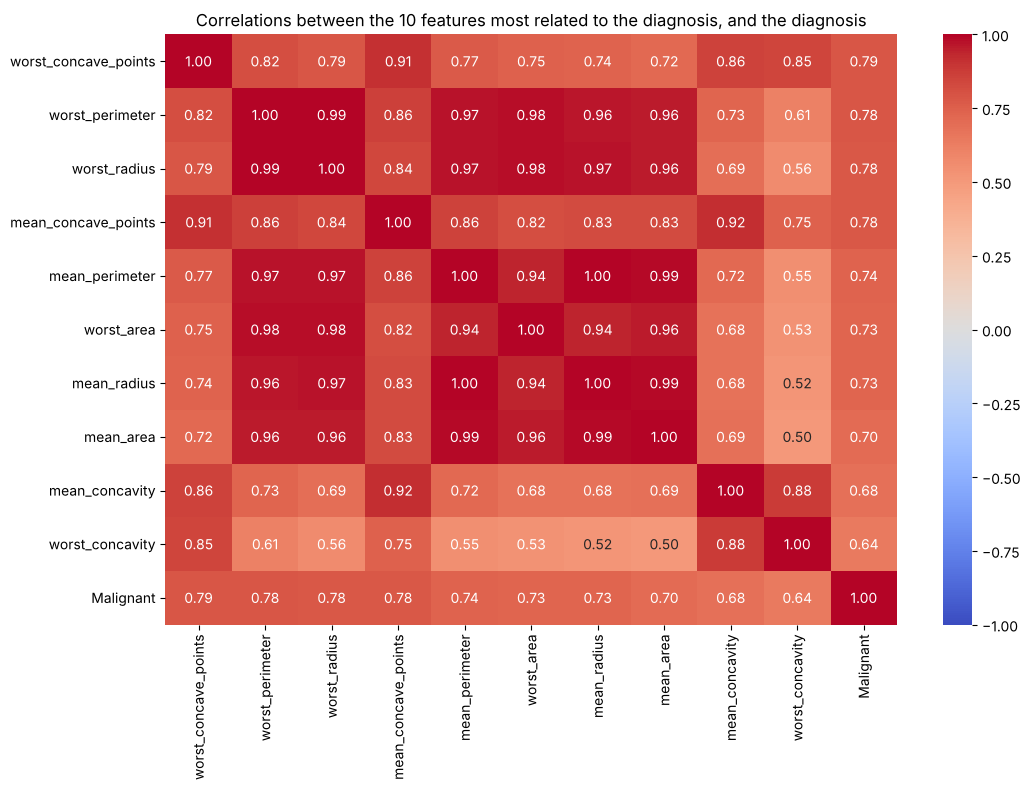

In [16]:
indices = list(order[:10]) + [len(columns)]  # positions of the top 10 + the diagnosis
names = [columns[i] for i in order[:10]] + ["Malignant"]  # their names
reduced_matrix = matrix[np.ix_(indices, indices)]  # sub-matrix with only those columns
plt.figure(figsize=(11, 8))  # large figure so the numbers fit
sns.heatmap(reduced_matrix, xticklabels=names, yticklabels=names, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)  # heat map with numbers
plt.title("Correlations between the 10 features most related to the diagnosis, and the diagnosis")  # title
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "05_top10_correlations.png", bbox_inches="tight")  # save the image
plt.show()  # show it

**What we see:** the size features (radius, perimeter, area) form an almost perfect red block: they measure the same thing.

### Cell 17: how many features are repeated among themselves?

We count how many feature pairs carry almost the same information (|r| > 0.9).

In [17]:
feature_correlation = np.corrcoef(X, rowvar=False)  # correlation between the 30 features (without the diagnosis)
upper_part = np.triu_indices(len(columns), k=1)  # positions above the diagonal: each pair only once
high_pairs = np.abs(feature_correlation[upper_part]) > 0.9  # True if the pair has |correlation| > 0.9
print("Feature pairs with |r| > 0.9:", int(high_pairs.sum()), "of", len(high_pairs))  # how many pairs
j = columns.index("mean_radius")  # position of mean_radius
print("mean_radius with mean_perimeter:", round(float(feature_correlation[j, columns.index("mean_perimeter")]), 3))  # radius and perimeter
print("mean_radius with mean_area:", round(float(feature_correlation[j, columns.index("mean_area")]), 3))  # radius and area

Feature pairs with |r| > 0.9: 21 of 435
mean_radius with mean_perimeter: 0.998
mean_radius with mean_area: 0.987


**What we see:** **21 pairs** out of 435 with |r| > 0.9; `mean_radius` with `mean_perimeter` has r = 0.998.

**Decision / hypothesis:** this **violates the independence** that Naive Bayes assumes (it counts the same evidence several times) and is what we will test in Phase 6 through calibration.

### Cell 18: the two best features against the diagnosis

The two best features against the diagnosis: can the difference be seen by eye?

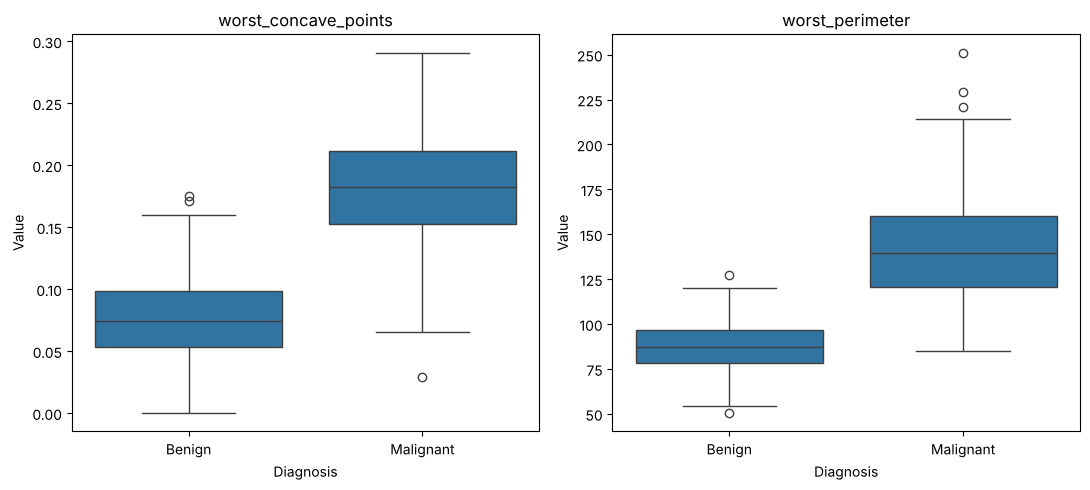

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))  # two plots side by side
for ax, i in zip(axes, order[:2]):  # the two most related features
    sns.boxplot(x=y, y=X[:, i], ax=ax)  # box of the feature by diagnosis (0 = benign, 1 = malignant)
    ax.set_xticks([0, 1])  # ticks at 0 and 1
    ax.set_xticklabels(["Benign", "Malignant"])  # name of each type
    ax.set_title(columns[i])  # title: feature name
    ax.set_xlabel("Diagnosis")  # horizontal axis
    ax.set_ylabel("Value")  # vertical axis
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "06_feature_vs_diagnosis.png", bbox_inches="tight")  # save the image
plt.show()  # show it

**What we see:** the benign and malignant boxes barely overlap.

### Cell 19: does a single feature separate almost everything?

**Ceiling-effect check.** What would the dumbest possible model get: a single feature with a single threshold?

In [19]:
best = columns[order[0]]  # the feature most related to the diagnosis
values = train[best].to_numpy()  # its values
thresholds = np.linspace(values.min(), values.max(), 200)  # 200 test thresholds between the minimum and the maximum
hits = [np.mean((values > t) == (y == 1)) for t in thresholds]  # fraction of correct answers if we say "malignant" when the value exceeds the threshold
print(f"With a single threshold on {best} we get {max(hits):.1%} of the cases right")  # best result
print(f"Always predicting 'benign' gets {np.mean(y == 0):.1%}")  # what the baseline gets

With a single threshold on worst_concave_points we get 91.9% of the cases right
Always predicting 'benign' gets 62.6%


**What we see:** with **a single threshold** on `worst_concave_points` we get **91.9%** right, against 62.6% for "always benign".

**Decision / hypothesis:** there is a **ceiling effect**. Every reasonable model will score very high and differences will be small, so we need repeated validation and statistical tests to know whether a difference is real or noise (Phase 3).

## Summary of the Phase 2 decisions

| What we saw | Decision for the next phases |
|---|---|
| 62.6% benign / 37.4% malignant | stratified splits; main metric **MCC**, not accuracy; baseline = "always benign" |
| Medians up to 218,000 times apart | **standardize** for SVM, MLP and evolutionary (inside each fold) |
| 0 nulls, 0 NaN, 0 duplicates | no imputation or cleaning |
| 30% of tumours with outliers (52% of the malignant ones) | **do not remove** outliers |
| 23 of 30 features with skewness > 1 | `log1p` as an option to test; not for the tree |
| 21 pairs with \|r\| > 0.9 | Naive Bayes will see repeated evidence → poor calibration expected |
| A single threshold gets 91.9% | **ceiling effect**: repetitions and statistical tests are needed |

**Next:** Phase 3 · Methodology (how we will evaluate fairly).
